### **Анализ данных и проверка гипотез о чаевых в ресторане**

### Цель

Сформулировать и проверить несколько простых гипотез о размере счета и чаевых с помощью статистики, группировок и визуализаций.

### Выполнила: Квасова-Изотова Анна Владимировна
---


## 1. Загрузка и описание данных

Необходимо:

1. Импортировать библиотеки.
2. Загрузить датасет `tips`.
3. Вывести первые строки.
4. Вывести `info()`.
5. Описать переменные своими словами.




In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px


In [2]:
tips = sns.load_dataset('tips')

tips.head()

tips.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


**Вывод**

В таблице представлены следующие переменные:
1. `total_bill`	- общая сумма счёта (без чаевых)
2. `tip`- чаевые
3. `sex` - пол клиента
4. `smoker`	- статус курения
5. `day`	- день недели
6. `time`	- время посещения
7. `size`	- размер компании

---

## 2. Проверка данных перед анализом

Необходимо:

1. Проверить пропуски.
2. Проверить дубликаты.
3. Проверить уникальные значения категориальных переменных.
4. Посчитать количество наблюдений по категориям `day` и `time`.
5. Сделать вывод.





In [3]:
display(pd.DataFrame({'Пропуски': tips.isna().sum()}))

display(tips.duplicated().sum())

print()
print('Строки-дубликаты:')
display(tips[tips.duplicated(keep=False)])

print()
print('Пол:')
display(tips['sex'].unique())
print()
print('Курит:')
display(tips['smoker'].unique())
print()


print('День:')
display(tips['day'].unique())


print()
print('Время:')
display(tips['time'].unique())

print()
display(pd.DataFrame({'Число чеков по дням': tips['day'].value_counts(dropna=False)}))
display(pd.DataFrame({'Число чеков по времени': tips['time'].value_counts(dropna=False)}))


,Пропуски
total_bill,0
tip,0
sex,0
smoker,0
day,0
time,0
size,0


np.int64(1)


Строки-дубликаты:


,total_bill,tip,sex,smoker,day,time,size
198,13.0,2.0,Female,Yes,Thur,Lunch,2
202,13.0,2.0,Female,Yes,Thur,Lunch,2



Пол:


...

['Sun', 'Sat', 'Thur', 'Fri']
Categories (4, object): ['Thur', 'Fri', 'Sat', 'Sun']


Время:


['Dinner', 'Lunch']
Categories (2, object): ['Lunch', 'Dinner']

,Число чеков по дням
day,
Sat,87
Sun,76
Thur,62
Fri,19


,Число чеков по времени
time,
Dinner,176
Lunch,68


В ходе проверки данных `tips` я выяснила следующее:

1. Пропусков нет - во всех столбцах isna().sum() показал 0.

2. Полных дубликатов - 1 пара. Открыла её через `keep=False`, увидела две полностью одинаковые строки. Но по лекции 3.3 одно совпадение признаков не доказывает, что это ошибка. Одна строка в `tips` - один чек. Вполне возможно, что это два разных чека: дело было в четверг на обеде, а в обеденное время посещаемость выше. Удалять их не стала.

3. Уникальные значения категориальных столбцов корректны - без опечаток и лишних пробелов. В day нет понедельника, вторника и среды - вероятно, потому что эти дни наименее загружены.

4. *По дням* больше всего чеков в субботу (87), меньше всего - в пятницу (19), что нетипично мало по сравнению с остальными днями. Причина такой разницы не указана - возможно была неполная выгрузка данных или в этот день ресторан работал не полный день.

    *По времени:* ужинов (176) - это в 2,6 раза больше, чем обедов (68).

**Вывод:** датасет пригоден к анализу - пропусков нет, найденный дубликат оставлен обоснованно, категории корректные.

---

## Гипотеза 1: чем больше счёт, тем больше чаевые

Необходимо:

1. Построить scatter plot `total_bill` — `tip`.
2. Добавить линию регрессии.
3. Посчитать корреляцию.
4. Найти несколько исключений: большие счета с относительно маленькими чаевыми.
5. Сделать вывод: подтверждается ли гипотеза.

Вопросы:

- Насколько сильная связь?
- Есть ли исключения?
- Всегда ли крупный счет означает крупные чаевые?





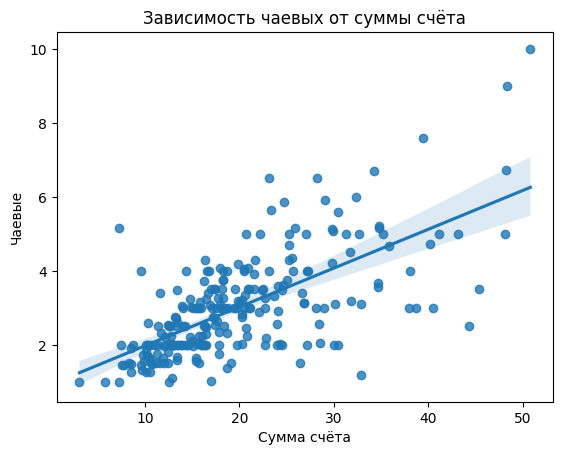

Корреляция:
Пирсон: 0.68
Спирмен: 0.68



,total_bill,tip,sex,smoker,day,time,size
57,26.41,1.50,Female,No,Sat,Dinner,2
237,32.83,1.17,Male,Yes,Sat,Dinner,2


In [4]:
sns.regplot(data=tips, x="total_bill", y="tip")

plt.title("Зависимость чаевых от суммы счёта")
plt.xlabel("Сумма счёта")
plt.ylabel("Чаевые")
plt.show()

print('Корреляция:')
pearson_r = tips['total_bill'].corr(tips['tip'], method='pearson').round(2)
spearman_r = tips['total_bill'].corr(tips['tip'], method='spearman').round(2)
print('Пирсон:', pearson_r)
print('Спирмен:', spearman_r)

print()
tips[['total_bill', 'tip']].describe().round(2)
tips[(tips['total_bill'] > 24) & (tips['tip'] < 2)]


**Выводы:**

**1) Насколько сильная связь?**

Связь есть, она умеренная. Корреляция 0.68. В лекции 4.3, раздел 21, подраздел 21.1 было указано, что диапазон от 0.3 до 0.7 - умеренная положительная связь.

**2) Есть ли исключения?**

Да, 2:

- счёт 26.41 с чаевыми 1.50;

- счёт 32.83 с чаевыми 1.17.

Оба счёта были сделаны в субботу, во время ужина, присутствовало 2 человека. Счёт был большим, но чаевые маленькими.

**3) Всегда ли крупный счет означает крупные чаевые?**
В среднем - да, что наглядно показано на графике, но не всегда. 2 исключения доказывают, что большой счёт не всегда означает большие чаевые.

---

## Гипотеза 2: на ужине чаевые выше, чем на обеде

Необходимо:

1. Создать `tip_percent`.
2. Рассчитать средние и медианные чаевые по `time`.
3. Рассчитать средний `tip_percent` по `time`.
4. Построить barplot и boxplot для сравнения `Lunch` и `Dinner`.
5. Сделать вывод.

Вопросы:

- Где выше абсолютные чаевые?
- Где выше процент чаевых?
- Отличается ли разброс значений?





Средние и медианные чаевые:


,mean,median
time,,
Lunch,2.73,2.25
Dinner,3.10,3.00



Процент чаевых:


,mean
time,
Lunch,16.41
Dinner,15.95


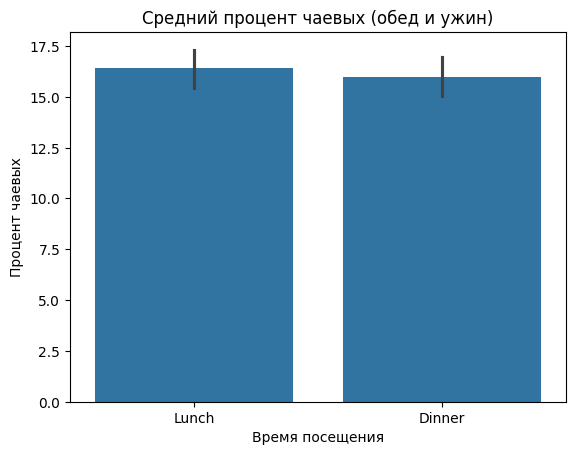

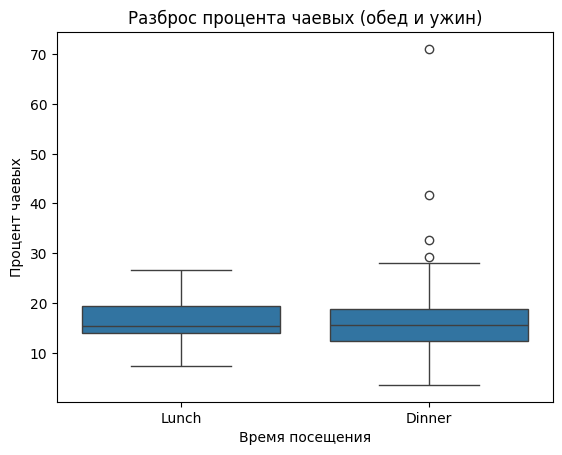

In [5]:
tips['tip_percent'] = tips['tip'] / tips['total_bill'] * 100

print('Средние и медианные чаевые:')
display(tips.groupby('time', observed=False)['tip'].agg(['mean', 'median']).round(2))

print()
print('Процент чаевых:')
display(tips.groupby('time', observed=False)['tip_percent'].agg(['mean']).round(2))

sns.barplot(data=tips, x="time", y="tip_percent")
plt.title("Средний процент чаевых (обед и ужин)")
plt.xlabel("Время посещения")
plt.ylabel("Процент чаевых")
plt.show()

sns.boxplot(data=tips, x="time", y="tip_percent")
plt.title("Разброс процента чаевых (обед и ужин)")
plt.xlabel("Время посещения")
plt.ylabel("Процент чаевых")
plt.show()


**1) Где выше абсолютные чаевые?**

По абсолютным чаевым показатели на ужине выше: среднее 3.10 - это на 0,37 выше, чем на обеде (2.73). Медиана тоже выше: 3.00 против 2.25.

**2) Где выше процент чаевых?**

По проценту чаевых ситуация обратная: на обеде 16.41%, на ужине 15.95%. Т.е. на обеде оставляют больший процент от счёта, чем на ужине.

**3) Отличается ли разброс значений?**

По разбросу (boxplot): на ужине больше выбросов - есть чеки с очень высоким процентом чаевых (до 30%, 45%, 70%). На обеде такого нет - разброс более ровный.

**Вывод:** средние и медианные чаевые больше во время ужина, процент чаевых выше во время обеда, но не намного. Гипотеза подтверждается частично - зависит от того, что понимать под выражением "больше чаевых" - сколько оставили денег или какую долю от счёта.

---

## Гипотеза 3: в разные дни недели чаевые отличаются

Необходимо:

1. Рассчитать средний `tip` по `day`.
2. Рассчитать средний `total_bill` по `day`.
3. Рассчитать средний `tip_percent` по `day`.
4. Построить barplot среднего `tip` по `day`.
5. Сделать вывод.

Вопросы:

- В какие дни чаевые выше?
- Совпадает ли высокий счет с высоким процентом чаевых?
- Можно ли выделить самый «щедрый» день?




Средние чаевые в день:


,mean
day,
Thur,2.77
Fri,2.73
Sat,2.99
Sun,3.26



Итоговый счёт в день:


,mean
day,
Thur,17.68
Fri,17.15
Sat,20.44
Sun,21.41



Процент чаевых в день:


,mean
day,
Thur,16.13
Fri,16.99
Sat,15.32
Sun,16.69


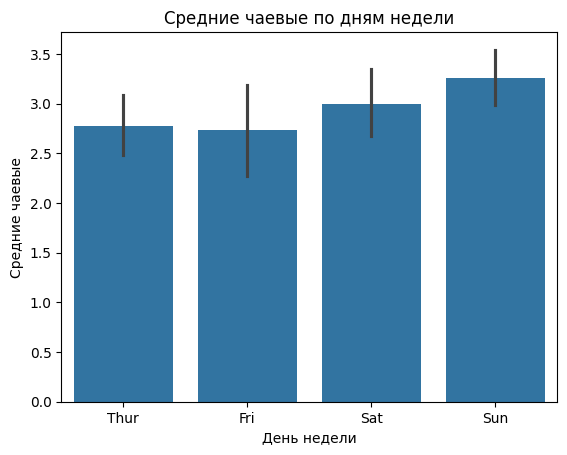

In [6]:
print('Средние чаевые в день:')
display(tips.groupby('day', observed=False)['tip'].agg(['mean']).round(2))

print()
print('Итоговый счёт в день:')
display(tips.groupby('day', observed=False)['total_bill'].agg(['mean']).round(2))

print()
print('Процент чаевых в день:')
display(tips.groupby('day', observed=False)['tip_percent'].agg(['mean']).round(2))

sns.barplot(data=tips, x="day", y="tip")
plt.title("Средние чаевые по дням недели")
plt.xlabel("День недели")
plt.ylabel("Средние чаевые")
plt.show()


**1) В какие дни чаевые выше?**

По чаевым лидирует воскресенье (в среднем 3.26), самый низкий - пятница (2.73). Разница между этими днями - 0.53.

По проценту чаевых лидирует пятница (16.99 %), а самый низкий показатель - суббота (15.32 %). Разница - 1.67 %


Ограничение: пятница представлена всего 19 чеками - маленькая выборка. Средние для этого дня менее надёжны. Это нужно учитывать.

**2) Совпадает ли высокий счет с высоким процентом чаевых?**

Нет, не совпадает.

По счёту картина следующая: воскресенье (21.41), суббота (20.44), четверг (17.68), пятница (17.15).

По проценту: пятница (16.99), воскресенье (16.69), четверг (16.13), суббота (15.32).

Порядок обратный: где счета высокие (суббота, воскресенье) - там процент не максимальный. А где счета низкие (пятница) - там процент самый высокий.

Значит, что большой счёт никак не связан с большим процентом.

**3) Можно ли выделить самый "щедрый" день?**

Зависит от определения "щедрости":

- Если щедрость - это сколько денег оставили, то лидирует воскресенье (3.26).

- Если щедрость - это какую долю от счёта оставили, то пятница (16.99).

**Вывод:**
Гипотеза подтвердилась: дни недели отличаются и по чаевым, и по проценту.
По счёту лидер воскресенье (21.41), минимальные значения в пятницу (17.15). А по процентам пятница лидирует (16.99%), минимальные значения в субботу (15.32%)

Т. е. где счёт большой - там большие и чаевые, но не обязательно, что и процент.

---

## Гипотеза 4: размер компании влияет на счет и чаевые

Необходимо:

1. Рассчитать средний `total_bill` по `size`.
2. Рассчитать средний `tip` по `size`.
3. Рассчитать средний `tip_percent` по `size`.
4. Построить lineplot для этих показателей.
5. Сделать вывод.

Вопросы:

- Растет ли счет с размером компании?
- Растут ли чаевые?
- Увеличивается ли процент чаевых?




Количество чеков по размеру компании:


,count
size,
2,156
3,38
4,37
5,5
1,4
6,4


Средний счёт по размеру компании:


,mean
size,
1,7.24
2,16.45
3,23.28
4,28.61
5,30.07
6,34.83



Чаевые по размеру компании:


,mean
size,
1,1.44
2,2.58
3,3.39
4,4.14
5,4.03
6,5.22



Процент чаевых по размеру компании:


,mean
size,
1,21.73
2,16.57
3,15.22
4,14.59
5,14.15
6,15.62


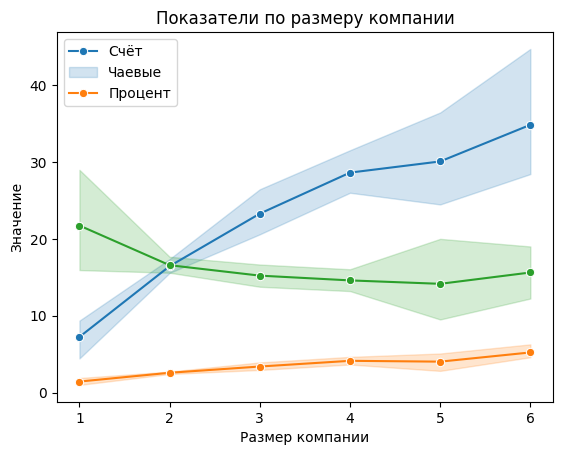

In [7]:
print('Количество чеков по размеру компании:')
display(tips['size'].value_counts())

print('Средний счёт по размеру компании:')
display(tips.groupby('size', observed=False)['total_bill'].agg(['mean']).round(2))

print()
print('Чаевые по размеру компании:')
display(tips.groupby('size', observed=False)['tip'].agg(['mean']).round(2))

print()
print('Процент чаевых по размеру компании:')
display(tips.groupby('size', observed=False)['tip_percent'].agg(['mean']).round(2))

sns.lineplot(data=tips, x="size", y="total_bill", marker="o")
sns.lineplot(data=tips, x="size", y="tip", marker="o")
sns.lineplot(data=tips, x="size", y="tip_percent", marker="o")
plt.title("Показатели по размеру компании")
plt.xlabel("Размер компании")
plt.ylabel("Значение")
plt.legend(["Счёт", "Чаевые", "Процент"])
plt.show()


**1) Растет ли счет с размером компании?**

Да, счёт растёт:

1 человек - 7.24

2 человека - 16.45

3 человека - 23.28

4 человека - 28.61

5 человек - 30.07

6 человек - 34.83

**2) Растут ли чаевые?**

Да, чаевые растут:

1 человек - 1.44

2 человека -  2.58

3 человека - 3.39

4 человека - 4.14

5 человек - 4.03

6 человек - 5.22

Есть небольшой откат на компании в 5 человек, но в общем чаевые растут.

**3) Увеличивается ли процент чаевых?**

Нет, процент чаевых уменьшается:

1 человек - 21.73%

2 человека - 16.57%

3 человека - 15.22%

4 человека - 14.59%

5 человек - 14.15%

6 человек - 15.62%

У размеров 1, 5 и 6 - мало данных (всего 4–5 чеков). Их средние значения могут быть случайными. А вот у размеров 2, 3 и 4 чеков много и там видно чётко - чем больше компания, тем меньше процент чаевых.

**Вывод:** гипотеза "размер компании влияет на счёт и чаевые" подтверждается.

Счёт и чаевые в деньгах растут вместе с размером компании.

Процент чаевых падает - маленькие компании оставляют большую долю от счёта, большие - меньшую.

Но для размеров 1, 5, 6 человек данных мало и вывод по ним может быть ненадёжен.


---

## Гипотеза 5: комбинации факторов важнее одного признака

Проверьте, отличаются ли чаевые в комбинациях групп.

Необходимо:

1. Создать сводную таблицу среднего `tip` по `day` и `time`.
2. Создать сводную таблицу среднего `tip_percent` по `smoker` и `sex`.
3. Построить heatmap для обеих таблиц.
4. Сравнить выводы с предыдущими заданиями.
5. Сделать вывод: дает ли сочетание факторов больше информации.

Вопросы:

- Какие комбинации категорий выделяются?
- Может ли один фактор скрывать различия внутри групп?
- Какие гипотезы требуют более детальной проверки?




Средние чаевые по дням недели и времени посещения:


time,Lunch,Dinner
day,,
Thur,2.77,3.00
Fri,2.38,2.94
Sat,NaN,2.99
Sun,NaN,3.26



Средний процент чаевых по статусу курения и полу:


smoker,Yes,No
sex,,
Male,22.28,19.79
Female,17.98,18.11


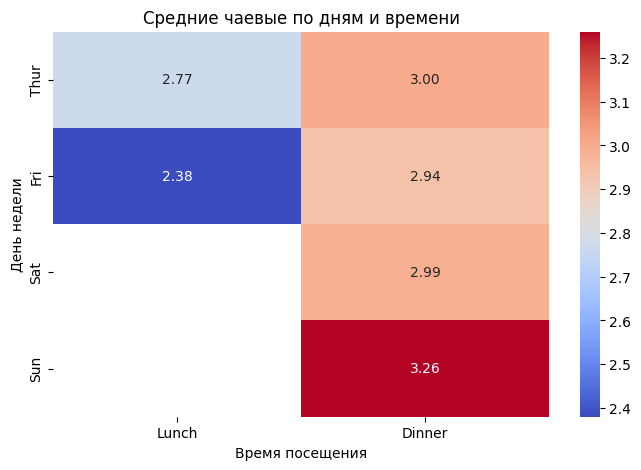

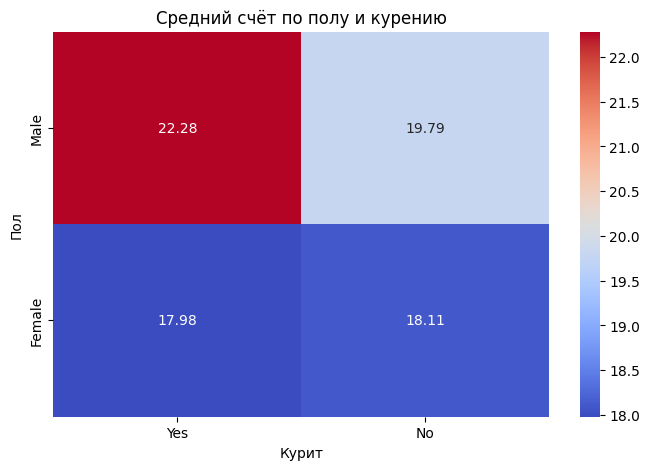

In [8]:
print('Средние чаевые по дням недели и времени посещения:')
display(tips.pivot_table(
    index='day',
    columns='time',
    values='tip',
    aggfunc='mean',
    observed=False
).round(2))

print()
print('Средний процент чаевых по статусу курения и полу:')
display(tips.pivot_table(
    index='sex',
    columns='smoker',
    values='total_bill',
    aggfunc='mean',
    observed=False
).round(2))

pivot1 = tips.pivot_table(
    index='day',
    columns='time',
    values='tip',
    aggfunc='mean',
    observed=False
).round(2)

pivot2 = tips.pivot_table(
    index='sex',
    columns='smoker',
    values='total_bill',
    aggfunc='mean',
    observed=False
).round(2)

plt.figure(figsize=(8, 5))
sns.heatmap(pivot1, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Средние чаевые по дням и времени')
plt.xlabel('Время посещения')
plt.ylabel('День недели')
plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(pivot2, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Средний счёт по полу и курению')
plt.xlabel('Курит')
plt.ylabel('Пол')
plt.show()


**4) Сравнить выводы с предыдущими заданиями.**

*Задание 4:*

Абсолютные чаевые выше на ужине и данные из 7 задания это подтверждают. В те дни, где есть обе смены, ужин выше обеда (3.00 > 2.77, 2.94 > 2.38), т.е. вывод из задания 4 основан не только на данных в целом, но и на каждом дне по отдельности.

*Задание 5:*

По абсолютным чаевым дополняет задание 5. Там пятница (2.73) была минимумом (хотя по проценту - лидером), но это среднее по обеим сменам. В задании 7 видно, что в пятницу обед (2.38), ужин (2.94), т.е. минимум пятницы приходится именно на обед, а ужин в пятницу не самый низкий. Лидерство воскресенья (3.26) подтверждается.

---
*Задание 3:*

В задании 3 речь идёт про корреляцию `total_bill` и `tip` по всем чекам, здесь `tip` по дню недели и времени, а `tip_percent` по полу и статусу курения. Общих признаков нет, проверять нечего.

*Задание 6:*  

В задании 6 речь идёт про размер компании, в задании 7 этот признак не используется. Выводы задания 6 о росте счёта/чаевых и падении процента задание 7 не подтверждает и не опровергает.

**5) Сделать вывод: дает ли сочетание факторов больше информации.**

Сочетание факторов даёт больше информации, чем один признак.

*Таблица 1 (чаевые по дню недели и времени):*  по показателю чаевых во все дни ужин лидирует над обедом. Но разница неодинаковая - в пятницу она больше, в четверг меньше. Одного признака было бы мало, чтобы это увидеть.

*Таблица 2 (процент чаевых по полу и статусу курения):*  курящие мужчины резко выделяются (22.28%), у женщин разницы почти нет. По одному признаку такого контраста не видно.

**Вывод:** сочетание нескольких факторов помогает увидеть то, что скрыто при анализе одного признака.
______________________________________________________________________

**1) Какие комбинации категорий выделяются?**

*Таблица 1 (чаевые по дню недели и времени):*

Максимальные чаевые: ужин в воскресенье - 3.26; минимальные: обед в пятницу - 2.38.

Выделяется ужин в воскресенье.

*Таблица 2 (процент чаевых по полу и статусу курения):*

Максимальный процент чаевых у курящих мужчин - 22.28 % (большой отрыв от некурящих мужчин - 19.79 %); минимальный у некурящих женщин - 18.11 % (небольшой отрыв от курящих женщин 17.98 %).

Выделяются курящие мужчины.

**2) Может ли один фактор скрывать различия внутри групп?**

Да, может. Один фактор усредняет показатели, чтобы увидеть картину целиком, нужно использовать несколько признаков сразу.

*Пример, таблица 1 (чаевые по дню недели и времени):*
в задании 4 мы изучали обед и ужин в целом - в среднем ужин больше обеда на 0.37. Но когда добавили дни недели, увидели, что разница не везде одинаковая: в четверг всего 0.23, а в пятницу - 0.56. В задании 4 было видно только общее среднее, а разбивка по дням показала, что эта разница складывалась неравномерно.

**3) Какие гипотезы требуют более детальной проверки?**

*Гипотеза 1:* чем больше счет, тем больше чаевые - частично подтверждена. 2 исключения показывают, что большой счёт не всегда означает большие чаевые.

*Гипотеза 2:* на ужине чаевые выше, чем на обеде - частично подтверждена. Зависит от того, что понимать под выражением "больше чаевых" - сколько оставили денег или какую долю от счёта.

*Гипотеза 3:* в разные дни недели чаевые отличаются - подтвердилась: дни недели отличаются и по чаевым, и по проценту.

*Гипотеза 4:* размер компании влияет на счет и чаевые - подтвердилась, но с оговоркой: размер компании 1, 5, 6 человек - по 4–5 чеков, ненадёжны.

*Гипотеза 5:* комбинации факторов важнее одного признака.

Отсюда следует, что *гипотеза 2*  требует уточнения формулировки и дополнительной проверки. Она подтвердилась частично: в деньгах ужин больше, а в проценте - обед.

*Гипотеза 4* подтверждена, но с оговоркой: на размеры компаний 1, 5, 6 человек было 4–5 чеков, что мало для вывода.

*Гипотезы 1, 3 и 5* - подтверждены, дополнительной проверки не требуют.